# 7. Association Rules and Campaigns
## Part A — Basket quality, assignment coverage, and category review

Begin with observed transaction baskets, not customer-level unions of products. This notebook currently prepares audited inputs for rule mining; it does not yet generate rules or claim campaign effectiveness.

The selected six-cluster solution covers positive-tenure fitting customers. Pending customers remain in coverage reports but are excluded from the assigned-population exploratory analysis. Coverage is measured in both customers and baskets.

This workflow adapts the original group project's basket-analysis objective while replacing comma-based parsing and silent inner joins. Category mapping must be reviewed before category-level mining.

Dependencies for this part: pandas, matplotlib. Later rule mining will use mlxtend.

## 1. Imports and paths

In [76]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from utils.association_rules_functions import (
    prepare_baskets, attach_assignments, summarize_coverage,
    product_catalog, segment_basket_summary,
)

# Change this one path if the raw basket CSV is stored elsewhere.
basket_path = project_root / "data" / "raw" / "customer_basket.csv"
cluster_dir = project_root / "models" / "clustering"
register_path = cluster_dir / "customer_assignment_register_INCOMPLETE.csv"
output_dir = project_root / "data" / "basket_analysis"
table_dir = project_root / "reports" / "tables" / "association_rules"
figure_dir = project_root / "reports" / "figures" / "association_rules"
for directory in [output_dir, table_dir, figure_dir]:
    directory.mkdir(parents=True, exist_ok=True)

## 2. Load data and confirm schema
The register filename is intentionally incomplete while deferred cases remain. If a complete reviewed register is created later, change the path explicitly. No assignment model is fitted here.

In [77]:
baskets = pd.read_csv(basket_path)
register = pd.read_csv(register_path)
required_basket_columns = {"invoice_id", "customer_id", "list_of_goods"}
assert required_basket_columns.issubset(baskets.columns)
assert {"customer_id", "cluster", "segment_name", "assignment_status"}.issubset(register.columns)
assert len(baskets) > 0
assert register["customer_id"].notna().all() and register["customer_id"].is_unique
assert register.loc[register["cluster"].notna(), "segment_name"].notna().all()
assert register["cluster"].notna().equals(register["assignment_status"].eq("assigned_fitting")), (
    "Check assignment_status semantics before using this register."
)
print(f"Input transaction rows: {len(baskets):,}")
print(f"Distinct basket customers: {baskets['customer_id'].nunique():,}")
display(baskets.head())
display(register["assignment_status"].value_counts(dropna=False))

Input transaction rows: 100,000
Distinct basket customers: 25,025


,invoice_id,list_of_goods,customer_id
0,5062209,"['megaman zero 3', 'energy bar', 'pokemon viol...",4925
1,4272512,"['black beer', 'bramble', 'laptop', 'pokemon v...",19046
2,7121052,"['soup', 'shallot', 'cake', 'fresh bread', 'cr...",10318
3,5847748,"['soup', 'cooking oil', 'cereals', 'oil', 'dog...",27283
4,6336114,"['eggplant', 'mint green tea', 'oil', 'bacon',...",16072


assignment_status
assigned_fitting    33715
pending_review        345
Name: count, dtype: int64

## 3. Parse baskets and inspect transaction identifiers
Repeated items within a basket are reduced to presence/absence. Items are lowercased and whitespace-normalized; different product names are not merged by fuzzy matching. Malformed and empty baskets are retained for reporting. They are not treated as valid empty shopping events.

In [78]:
parsed = prepare_baskets(baskets)
parse_summary = parsed["parse_status"].value_counts(dropna=False).rename("rows").to_frame()
parse_summary["percentage"] = parse_summary["rows"] / len(parsed) * 100
display(parse_summary.round(2))

duplicate_invoice = parsed["invoice_id"].duplicated(keep=False) & parsed["invoice_id"].notna()
quality = pd.Series({
    "input_rows": len(parsed),
    "missing_invoice_id": int(parsed["invoice_id"].isna().sum()),
    "rows_with_duplicate_invoice_id": int(duplicate_invoice.sum()),
    "missing_customer_id": int(parsed["customer_id"].isna().sum()),
    "invalid_or_empty_baskets": int(parsed["parse_status"].ne("valid").sum()),
}, name="count")
display(quality)
display(parsed.loc[parsed["parse_status"].ne("valid"),
                   ["invoice_id", "customer_id", "list_of_goods", "parse_status"]].head(10))
parsed.loc[duplicate_invoice].to_csv(output_dir / "duplicate_invoice_rows.csv", index=False)
parsed.loc[parsed["parse_status"].ne("valid")].to_csv(output_dir / "basket_parse_review.csv", index=False)

,rows,percentage
parse_status,,
valid,100000,100.0


input_rows                        100000
missing_invoice_id                     0
rows_with_duplicate_invoice_id       743
missing_customer_id                    0
invalid_or_empty_baskets               0
Name: count, dtype: int64

,invoice_id,customer_id,list_of_goods,parse_status


In [79]:
# Set aside all rows whose invoice ID appears more than once.
ambiguous_invoice = parsed["invoice_id"].duplicated(keep=False)

ambiguous_baskets = parsed.loc[ambiguous_invoice].copy()
baskets_for_analysis = parsed.loc[~ambiguous_invoice].copy()

ambiguous_baskets["exclusion_reason"] = (
    "Repeated invoice ID linked to multiple customers; ownership unresolved"
)

ambiguous_baskets.to_csv(
    output_dir / "ambiguous_invoice_baskets.csv",
    index=False,
)

assert (
    len(baskets_for_analysis) + len(ambiguous_baskets)
    == len(parsed)
)

print(f"Original basket rows: {len(parsed):,}")
print(f"Rows set aside: {len(ambiguous_baskets):,}")
print(f"Rows retained: {len(baskets_for_analysis):,}")

Original basket rows: 100,000
Rows set aside: 743
Rows retained: 99,257


## 4. Join assignments and report coverage
A left join preserves pending and unmatched baskets. Check these categories before filtering. Distinct-customer counts in the coverage table concern customers represented in the basket file; they are not percentages of the full customer register.

In [80]:
basket_review = attach_assignments(
    baskets_for_analysis,
    register,
)

assert len(basket_review) == len(baskets_for_analysis)

coverage = summarize_coverage(basket_review)
display(coverage.round(2))
customer_coverage = register.assign(
    has_input_basket=register["customer_id"].isin(
        parsed["customer_id"].dropna()
    ),
    has_retained_basket=register["customer_id"].isin(
        baskets_for_analysis["customer_id"].dropna()
    ),
).groupby("assignment_status").agg(
    registered_customers=("customer_id", "size"),
    customers_with_input_baskets=("has_input_basket", "sum"),
    customers_with_retained_baskets=("has_retained_basket", "sum"),
)

customer_coverage["retained_customer_coverage_pct"] = (
    customer_coverage["customers_with_retained_baskets"]
    / customer_coverage["registered_customers"]
    * 100
)

display(customer_coverage.round(2))

,baskets,distinct_customers,basket_pct
coverage_status,,,
assigned,98247,24714,98.98
pending_or_unassigned,1010,263,1.02


,registered_customers,customers_with_input_baskets,customers_with_retained_baskets,retained_customer_coverage_pct
assignment_status,,,,
assigned_fitting,33715,24762,24714,73.30
pending_review,345,263,263,76.23


In [81]:
duplicate_rows = parsed.loc[
    parsed["invoice_id"].duplicated(keep=False)
].copy()

# Compare normalized basket contents without depending on product order.
duplicate_rows["basket_key"] = duplicate_rows["items"].apply(
    lambda items: tuple(sorted(items))
)

duplicate_summary = (
    duplicate_rows
    .groupby("invoice_id")
    .agg(
        rows=("invoice_id", "size"),
        distinct_customers=("customer_id", "nunique"),
        distinct_baskets=("basket_key", "nunique"),
    )
)

duplicate_summary["same_customer_and_basket"] = (
    duplicate_summary["distinct_customers"].eq(1)
    & duplicate_summary["distinct_baskets"].eq(1)
)

print(f"Rows in repeated-ID groups: {len(duplicate_rows):,}")
print(f"Repeated invoice IDs: {len(duplicate_summary):,}")

print(
    "IDs with one customer and one normalized basket:",
    duplicate_summary["same_customer_and_basket"].sum(),
)

print(
    "IDs with multiple customers:",
    duplicate_summary["distinct_customers"].gt(1).sum(),
)

print(
    "IDs with multiple basket contents:",
    duplicate_summary["distinct_baskets"].gt(1).sum(),
)

display(duplicate_summary.head(15))

display(
    duplicate_rows[
        ["invoice_id", "customer_id", "items"]
    ].sort_values(["invoice_id", "customer_id"]).head(30)
)

Rows in repeated-ID groups: 743
Repeated invoice IDs: 371
IDs with one customer and one normalized basket: 0
IDs with multiple customers: 371
IDs with multiple basket contents: 0


,rows,distinct_customers,distinct_baskets,same_customer_and_basket
invoice_id,,,,
41373,2,2,1,False
69085,2,2,1,False
70085,2,2,1,False
91179,2,2,1,False
140939,2,2,1,False
170913,2,2,1,False
196892,2,2,1,False
253578,2,2,1,False
276595,2,2,1,False


,invoice_id,customer_id,items
51146,41373,16248,"[napkins, pokemon shield, ketchup, ratchet & c..."
51145,41373,17210,"[napkins, pokemon shield, ketchup, ratchet & c..."
68030,69085,278,"[chutney, cottage cheese, laptop, frozen smoot..."
68029,69085,4858,"[chutney, cottage cheese, laptop, frozen smoot..."
6698,70085,17016,"[shampoo, soda, cake, shallot, samsung galaxy ..."
6697,70085,22768,"[shampoo, soda, cake, shallot, samsung galaxy ..."
58187,91179,26729,"[shampoo, napkins, ratchet & clank, milk, mayo..."
58188,91179,27689,"[shampoo, napkins, ratchet & clank, milk, mayo..."
63837,140939,1634,"[grated cheese, laptop, deodorant, champagne, ..."
63836,140939,7248,"[grated cheese, laptop, deodorant, champagne, ..."


### Identifier checkpoint
The old dataset has one record per invoice. Duplicate IDs may reflect repeated exports, conflicting records, or a different transaction schema. Inspect them rather than automatically dropping or merging rows. Stop here if duplicates or missing invoice IDs exist; resolve the source and rerun before counting basket support.

In [82]:
assert baskets_for_analysis["invoice_id"].notna().all()
assert baskets_for_analysis["invoice_id"].is_unique

eligible = (
    basket_review["coverage_status"].eq("assigned")
    & basket_review["parse_status"].eq("valid")
)

analysis_baskets = basket_review.loc[eligible].copy()

assert len(analysis_baskets) > 0

analysis_baskets["cluster"] = (
    analysis_baskets["cluster"].astype(int)
)

print(f"Eligible assigned baskets: {len(analysis_baskets):,}")

print(
    "Share of retained rows: "
    f"{len(analysis_baskets) / len(baskets_for_analysis):.2%}"
)

print(
    "Share of original input rows: "
    f"{len(analysis_baskets) / len(parsed):.2%}"
)

Eligible assigned baskets: 98,247
Share of retained rows: 98.98%
Share of original input rows: 98.25%


## 5. Basket composition by segment
Show customer and basket counts together. Customers with more sampled transactions contribute more to basket-level rules; those rules describe transactions, not equally weighted customer preferences.

,,baskets,customers,mean_basket_size,median_basket_size,baskets_per_customer
cluster,segment_name,,,,,
0,Established Multi-Category Shoppers,32012,8033,9.05,9.0,3.99
1,Electronics and Gaming Shoppers,10084,2560,8.98,9.0,3.94
2,"Low-Spending, Promotion-Oriented Shoppers",15470,3887,8.97,9.0,3.98
3,Promotion-Heavy Regular Shoppers,14940,3737,9.07,9.0,4.00
4,High-Spending Multi-Category Shoppers,12856,3284,8.99,9.0,3.91
5,Vegetable-Focused Shoppers,12885,3213,8.81,9.0,4.01


count    24714.000000
mean         3.975358
std          3.206385
min          1.000000
50%          3.000000
90%          8.000000
99%         15.000000
max         33.000000
Name: baskets_per_customer, dtype: float64

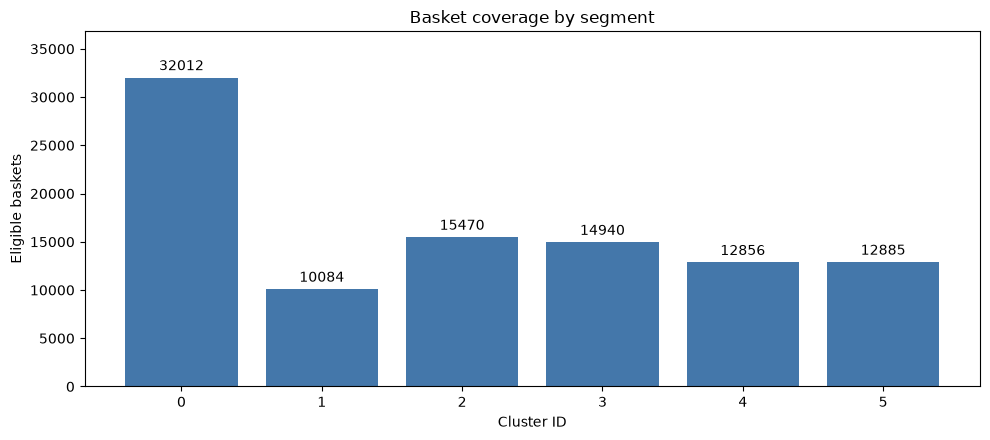

In [83]:
segment_summary = segment_basket_summary(analysis_baskets)
display(segment_summary.round(2))

basket_concentration = analysis_baskets.groupby("customer_id").size().describe(
    percentiles=[.5, .9, .99]
).rename("baskets_per_customer")
display(basket_concentration)

fig, ax = plt.subplots(figsize=(10, 4.5))
sizes = segment_summary.reset_index()
bars = ax.bar(sizes["cluster"].astype(str), sizes["baskets"], color="#4477AA")
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set(xlabel="Cluster ID", ylabel="Eligible baskets", title="Basket coverage by segment")
ax.margins(y=.15)
fig.tight_layout()
fig.savefig(figure_dir / "basket_counts_by_segment.png", dpi=160)
plt.show()

## 6. Product catalog and category-review file
Use one reviewed mapping for every segment. Do not treat 'uncategorized' as a meaningful category. No category is inferred from a short ambiguous substring in this version.

The catalog covers all valid parsed baskets, including pending/unmatched customers, so later coverage changes do not silently introduce unseen products. Frequency in assigned analysis baskets is reported separately.

On the first run the mapping file is created with blank categories. Review and save it; reruns preserve existing entries and append new product names. Category names should follow the reference list, with 'other' used only for a consciously reviewed miscellaneous group, not as a synonym for unknown.

In [84]:
all_valid = parsed.loc[parsed["parse_status"].eq("valid")]
catalog = product_catalog(all_valid)
assigned_catalog = product_catalog(analysis_baskets).rename(columns={
    "basket_count": "assigned_basket_count", "basket_pct": "assigned_basket_pct"
})
catalog = catalog.merge(assigned_catalog, on="product_name", how="left")
catalog[["assigned_basket_count", "assigned_basket_pct"]] = catalog[
    ["assigned_basket_count", "assigned_basket_pct"]
].fillna(0)
display(catalog.head(25).round(2))

allowed_categories = [
    "groceries", "electronics", "vegetables", "nonalcohol_drinks",
    "alcohol_drinks", "meat", "fish", "hygiene", "petfood", "videogames", "other",
]
mapping_path = output_dir / "product_category_mapping.csv"
if mapping_path.exists():
    previous = pd.read_csv(mapping_path).fillna("")
    assert previous["product_name"].is_unique
    mapping = catalog[["product_name"]].merge(previous, on="product_name", how="left").fillna("")
else:
    mapping = catalog[["product_name"]].copy()
    mapping["category"] = ""
    mapping["review_status"] = "pending"
    mapping["notes"] = ""
mapping.to_csv(mapping_path, index=False)
print("Allowed categories:", allowed_categories)
print(f"Distinct products to review: {len(mapping):,}")
display(mapping.head(15))

,product_name,basket_count,basket_pct,assigned_basket_count,assigned_basket_pct
0,oil,34900,34.90,34375,34.99
1,cooking oil,25052,25.05,24685,25.13
2,babies food,18067,18.07,17791,18.11
3,asparagus,15952,15.95,15712,15.99
4,cake,15134,15.13,14865,15.13
5,tomatoes,14523,14.52,14296,14.55
6,champagne,14195,14.19,13899,14.15
7,fresh tuna,12832,12.83,12628,12.85
8,ratchet & clank,12179,12.18,12004,12.22
9,candy bars,12091,12.09,11887,12.10


Allowed categories: ['groceries', 'electronics', 'vegetables', 'nonalcohol_drinks', 'alcohol_drinks', 'meat', 'fish', 'hygiene', 'petfood', 'videogames', 'other']
Distinct products to review: 164


,product_name,category,review_status,notes
0,oil,groceries,reviewed,Assumed edible oil; kept distinct from cooking...
1,cooking oil,groceries,reviewed,Name-based mapping accepted for this analysis;...
2,babies food,groceries,reviewed,Name-based mapping accepted for this analysis;...
3,asparagus,vegetables,reviewed,Name-based mapping accepted for this analysis;...
4,cake,groceries,reviewed,Name-based mapping accepted for this analysis;...
5,tomatoes,vegetables,reviewed,Name-based mapping accepted for this analysis;...
6,champagne,alcohol_drinks,reviewed,Name-based mapping accepted for this analysis;...
7,fresh tuna,fish,reviewed,Name-based mapping accepted for this analysis;...
8,ratchet & clank,videogames,reviewed,Name-based mapping accepted for this analysis;...
9,candy bars,groceries,reviewed,Name-based mapping accepted for this analysis;...


## 7. Mapping readiness
Mark approved entries with review_status = reviewed. Blank or unreviewed mappings are excluded from the mapping-coverage numerator. Product coverage and basket-item coverage are different; report both. Category-level mining will be added only after the mapping is inspected.

In [85]:
mapping = pd.read_csv(mapping_path).fillna("")
approved = mapping["review_status"].eq("reviewed") & mapping["category"].isin(allowed_categories)
lookup = mapping.loc[approved].set_index("product_name")["category"].to_dict()
product_occurrences = sum(len(items) for items in analysis_baskets["items"])
mapped_occurrences = sum(item in lookup for items in analysis_baskets["items"] for item in items)
readiness = pd.Series({
    "catalog_products": len(mapping),
    "reviewed_mapped_products": int(approved.sum()),
    "eligible_product_basket_occurrences": product_occurrences,
    "mapped_occurrences": mapped_occurrences,
    "mapped_occurrence_pct": mapped_occurrences / product_occurrences * 100,
}, name="value")
display(readiness.round(2))
print(
    "Accepted mapping loaded. "
    "Name-based assumptions remain documented in the notes."
)

catalog_products                          164.0
reviewed_mapped_products                  164.0
eligible_product_basket_occurrences    883666.0
mapped_occurrences                     883666.0
mapped_occurrence_pct                     100.0
Name: value, dtype: float64

Accepted mapping loaded. Name-based assumptions remain documented in the notes.


In [86]:
# Categories used for mining; exclude the ambiguous fallback.
mining_lookup = {
    product: category
    for product, category in lookup.items()
    if category != "other"
}

meaningful_occurrences = sum(
    product in mining_lookup
    for items in analysis_baskets["items"]
    for product in items
)

print(
    "Product–basket occurrences mapped to mining categories: "
    f"{meaningful_occurrences:,} / {product_occurrences:,} "
    f"({meaningful_occurrences / product_occurrences:.2%})"
)

# Each category appears at most once per basket.
analysis_baskets["category_items"] = analysis_baskets["items"].apply(
    lambda items: sorted({
        mining_lookup[product]
        for product in items
        if product in mining_lookup
    })
)

print(
    "Baskets with no mining categories:",
    analysis_baskets["category_items"].str.len().eq(0).sum(),
)

display(
    analysis_baskets[
        ["invoice_id", "cluster", "items", "category_items"]
    ].head()
)

Product–basket occurrences mapped to mining categories: 877,642 / 883,666 (99.32%)
Baskets with no mining categories: 0


,invoice_id,cluster,items,category_items
0,5062209,1,"[megaman zero 3, energy bar, pokemon violet, a...","[alcohol_drinks, electronics, groceries, nonal..."
1,4272512,1,"[black beer, bramble, laptop, pokemon violet, ...","[alcohol_drinks, electronics, groceries, nonal..."
2,7121052,4,"[soup, shallot, cake, fresh bread, cream, carr...","[groceries, meat, nonalcohol_drinks, vegetables]"
3,5847748,2,"[soup, cooking oil, cereals, oil, dog food, de...","[fish, groceries, hygiene, nonalcohol_drinks, ..."
4,6336114,3,"[eggplant, mint green tea, oil, bacon, toilet ...","[alcohol_drinks, fish, groceries, hygiene, mea..."


## 8. Export audited inputs
Items are serialized as JSON lists for reliable round-trip parsing. Preserve pending/unmatched coverage in a separate audit table. No rule or discount recommendation is generated at this stage.

In [87]:
export = analysis_baskets[["invoice_id", "customer_id", "cluster", "segment_name", "items", "basket_size"]].copy()
export["items"] = export["items"].apply(json.dumps)
export.to_csv(output_dir / "assigned_baskets_clean.csv", index=False)
basket_review.loc[~eligible, ["invoice_id", "customer_id", "coverage_status", "parse_status"]].to_csv(
    output_dir / "baskets_outside_analysis.csv", index=False
)
coverage.to_csv(table_dir / "basket_assignment_coverage.csv")
customer_coverage.to_csv(table_dir / "customer_basket_coverage.csv")
parse_summary.to_csv(table_dir / "basket_parse_summary.csv")
quality.to_csv(table_dir / "basket_quality.csv")
segment_summary.to_csv(table_dir / "segment_basket_summary.csv")
catalog.to_csv(table_dir / "product_catalog.csv", index=False)
readiness.to_csv(table_dir / "mapping_readiness.csv")
settings = {
    "scope": "Exploratory baskets of assigned customers only",
    "basket_source": str(basket_path.relative_to(project_root)),
    "register_source": str(register_path.relative_to(project_root)),
    "unit": "one invoice; unique product presence within basket",
    "normalization": (
        "lowercase; strip and collapse whitespace; no fuzzy matching"
    ),

    "duplicate_invoice_policy": (
        "All rows with repeated invoice IDs were set aside "
        "because customer ownership was unresolved"
    ),
    "ambiguous_invoice_rows": len(ambiguous_baskets),
    "retained_rows": len(baskets_for_analysis),

    "input_rows": len(baskets),
    "eligible_baskets": len(analysis_baskets),
    "eligible_customers": int(
        analysis_baskets["customer_id"].nunique()
    ),
    "rule_mining_status": (
        "not implemented pending basket and mapping review"
    ),
}

(output_dir / "basket_preparation_settings.json").write_text(
    json.dumps(settings, indent=2)
)

print(
    "Basket preparation exported. "
    "Review coverage and mapping before rule mining."
)

Basket preparation exported. Review coverage and mapping before rule mining.


In [88]:
basket_flow = pd.Series({
    "original_input_rows": len(parsed),
    "ambiguous_invoice_rows_set_aside": len(ambiguous_baskets),
    "retained_rows": len(baskets_for_analysis),
    "retained_rows_outside_analysis": int((~eligible).sum()),
    "eligible_assigned_baskets": len(analysis_baskets),
}, name="rows")

assert (
    basket_flow["ambiguous_invoice_rows_set_aside"]
    + basket_flow["retained_rows_outside_analysis"]
    + basket_flow["eligible_assigned_baskets"]
    == basket_flow["original_input_rows"]
)

display(basket_flow)

basket_flow.to_csv(
    table_dir / "basket_population_flow.csv"
)


original_input_rows                 100000
ambiguous_invoice_rows_set_aside       743
retained_rows                        99257
retained_rows_outside_analysis        1010
eligible_assigned_baskets            98247
Name: rows, dtype: int64

### Treatment of repeated invoice identifiers

The dataset contained 371 repeated invoice identifiers involving 743 rows.
Every repeated identifier was associated with multiple customers but one
normalized basket content.

These records were treated as ambiguous customer–transaction links.
The available data did not establish whether they represented reused
identifiers, duplicated customer links, or intentionally shared records.

All 743 affected rows were preserved in a separate audit file and excluded
from the baseline segment-specific basket analysis. No customer assignment
was changed, and no basket was allocated arbitrarily to a customer.

This treatment retained 99,257 transaction rows before assignment and
parsing eligibility filters. Coverage statistics were recalculated after
the exclusion.